# visual evaluation:

the original MRI `AORTA_274_0000.nii.gz`

the manual mask `sample_data\ao_segs\AORTA_274.nii.gz`

the inferenced mask `nnUNet_raw\Dataset201_AORTA_MRI\labelsTs\AORTA_274.nii.gz` 

In [1]:
import os
import random
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
BASE_DIR = os.path.dirname(os.path.abspath(os.getcwd()))
# print(BASE_DIR)
RAW_DATA_DIR = os.path.join(BASE_DIR, '/workspace/test_data')


DATA_DIR = Path(RAW_DATA_DIR)
AO_IMGS_DIR = DATA_DIR / "ao_imgs"
AO_SEGS_DIR = DATA_DIR / "ao_segs"
INFRENCED_DATA_DIR = Path(os.path.join(BASE_DIR, '/workspace/nnUNet_raw/Dataset301_RACLETTE_4DFLOW_AORTA')) / "labelsTs"
img_files = sorted(AO_IMGS_DIR.glob("*.nii.gz"))
seg_files = sorted(AO_SEGS_DIR.glob("*.nii.gz"))
infrenced_seg_files = sorted(INFRENCED_DATA_DIR.glob("*.nii.gz"))

print(f"Found {len(img_files)} images and {len(seg_files)} segmentations and infrenced segmentations {len(infrenced_seg_files)}")

Found 2350 images and 2350 segmentations and infrenced segmentations 2350


In [3]:
NUM_SAMPLES = 2350
random.seed(42)
sample_indices = random.sample(range(len(img_files)), NUM_SAMPLES)

sample_imgs = [img_files[i] for i in sample_indices]
sample_segs = [seg_files[i] for i in sample_indices]
sample_infrenced_segs = [infrenced_seg_files[i] for i in sample_indices]

print("Selected sample indices:", sample_indices)

Selected sample indices: [456, 102, 1126, 1003, 914, 571, 419, 2233, 356, 1728, 130, 122, 383, 895, 952, 2069, 108, 2298, 814, 2232, 1718, 902, 1839, 1139, 26, 653, 1731, 1393, 1138, 636, 881, 1378, 418, 379, 1556, 396, 1470, 1408, 1083, 177, 1881, 2196, 511, 1550, 322, 2261, 1200, 1481, 787, 284, 187, 933, 1185, 326, 953, 413, 2315, 2321, 1857, 1494, 666, 1516, 1455, 858, 1093, 292, 700, 2187, 1002, 669, 1893, 1554, 1105, 899, 1328, 229, 938, 131, 1292, 1643, 1096, 271, 864, 1288, 870, 2044, 1620, 1879, 585, 1084, 2344, 1010, 2207, 1076, 1754, 1635, 1482, 898, 566, 2087, 2021, 372, 192, 449, 626, 655, 1729, 260, 1576, 1563, 1917, 2167, 1029, 47, 469, 2199, 1092, 2322, 2349, 1202, 1780, 647, 1858, 13, 1078, 2050, 731, 2079, 435, 1222, 2222, 2331, 2245, 1531, 661, 2209, 2172, 2, 1327, 2001, 79, 458, 1486, 1259, 980, 237, 986, 2305, 350, 1990, 283, 2181, 515, 525, 1946, 676, 1085, 2161, 1733, 867, 823, 1276, 1634, 1529, 1794, 2119, 1849, 495, 1015, 920, 262, 1384, 86, 942, 2328, 29, 290,

In [5]:
def load_nifti(filepath):
    img = nib.load(str(filepath))
    return img.get_fdata(), img.affine, img.header
    
def visualize_mip(img_data, seg_data):
    mip_img = np.max(img_data, axis=2)
    mip_seg = np.max(seg_data, axis=2)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(mip_img.T, cmap="gray", origin="lower")
    plt.title("MIP - MRI Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mip_seg.T, cmap="jet", origin="lower")
    plt.title("MIP - Segmentation")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(mip_img.T, cmap="gray", origin="lower")
    plt.imshow(mip_seg.T, cmap="jet", alpha=0.5, origin="lower")
    plt.title("MIP - Overlay")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# print("MANUAL SEGMENTATION")
# for img_path, seg_path in zip(sample_imgs, sample_segs):
#     img_data, _, _ = load_nifti(img_path)
#     seg_data, _, _ = load_nifti(seg_path)
#     print(f"Image: {img_path.name}")
#     visualize_mip(img_data, seg_data)
#     print("-" * 80)

# print("INFRENCED SEGMENTATION")

# for img_path, seg_path in zip(sample_imgs, sample_infrenced_segs):
#     img_data, _, _ = load_nifti(img_path)
#     seg_data, _, _ = load_nifti(seg_path)
#     print(f"Image: {img_path.name}")
#     visualize_mip(img_data, seg_data)
#     print("-" * 80)


COMPARISON: MANUAL vs INFERRED
Image: VS022_f06_0000.nii.gz


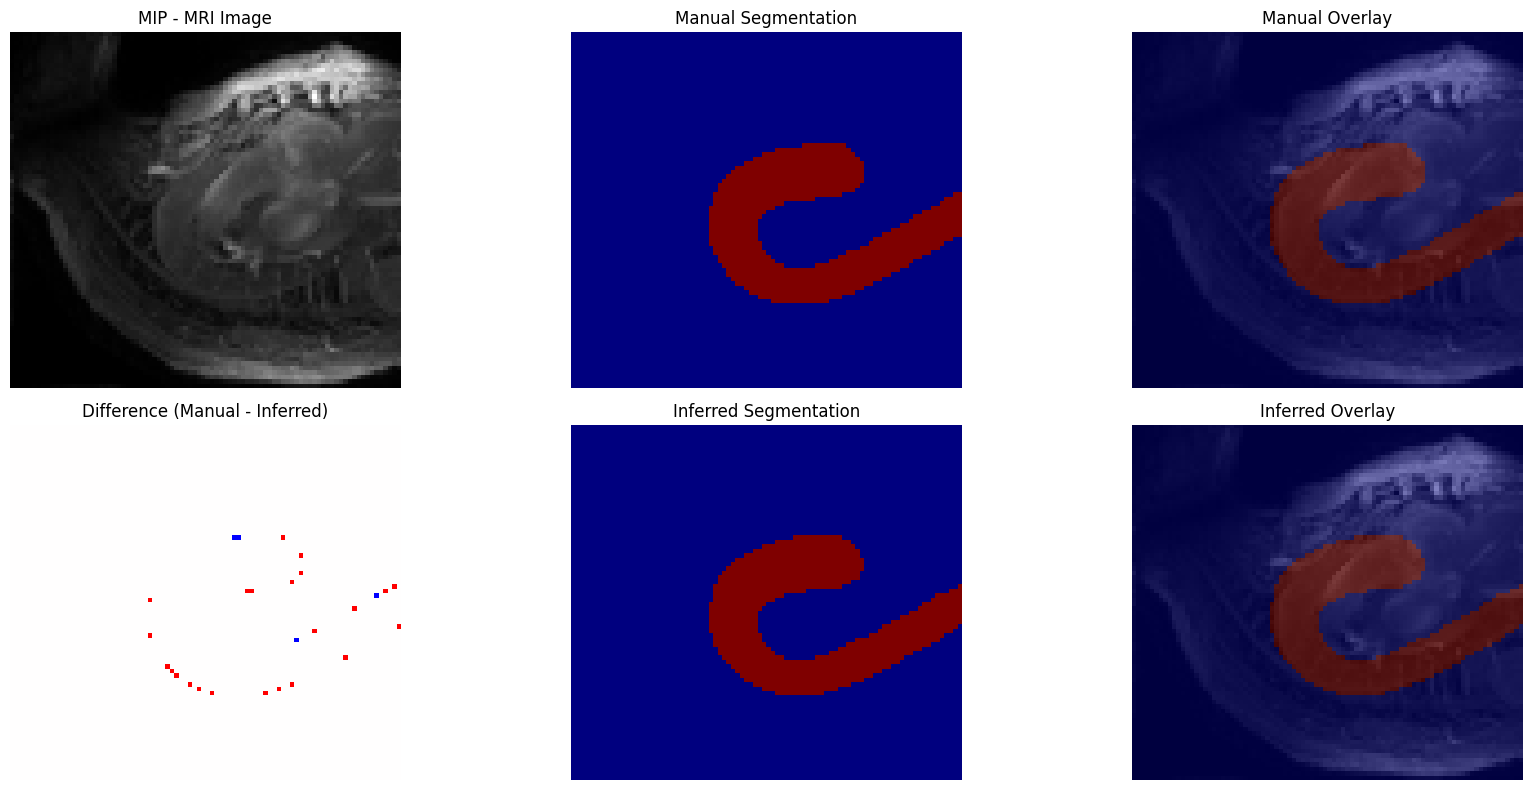

--------------------------------------------------------------------------------
Image: VS005_f02_0000.nii.gz


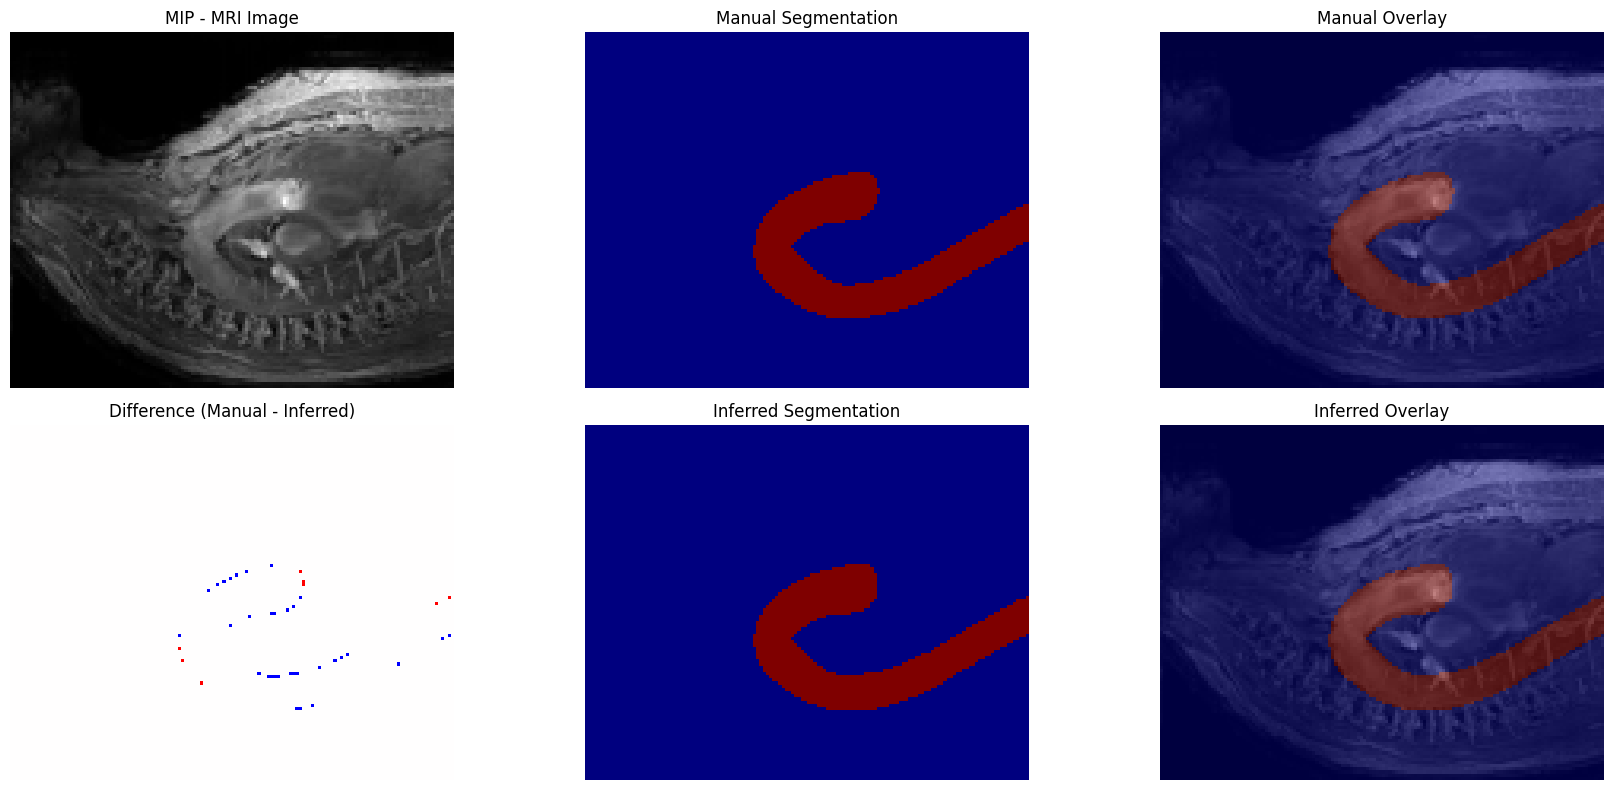

--------------------------------------------------------------------------------
Image: VS052_f01_0000.nii.gz


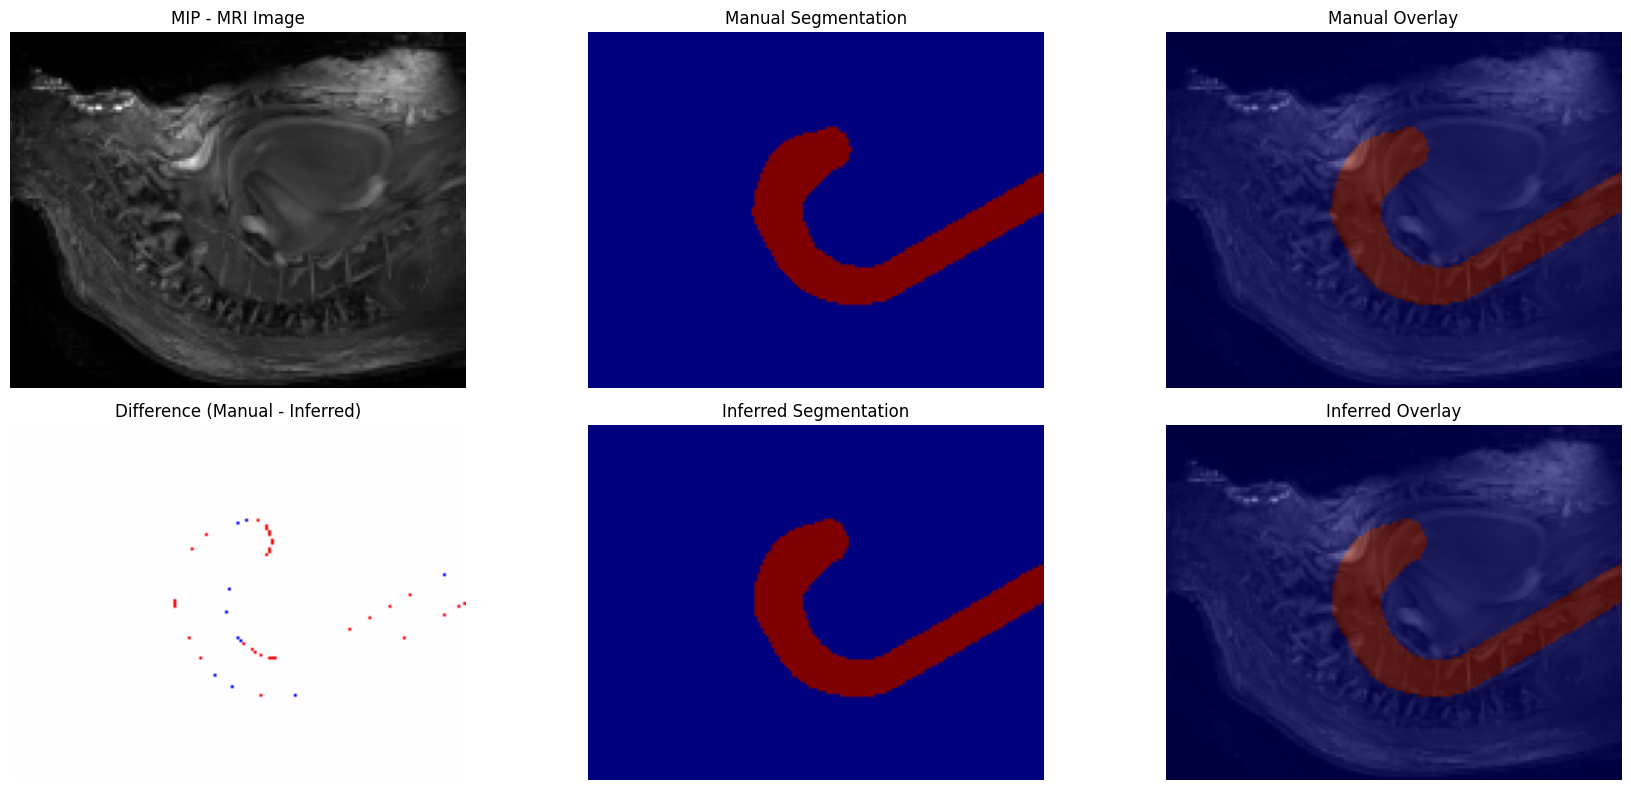

--------------------------------------------------------------------------------
Image: VS047_f03_0000.nii.gz


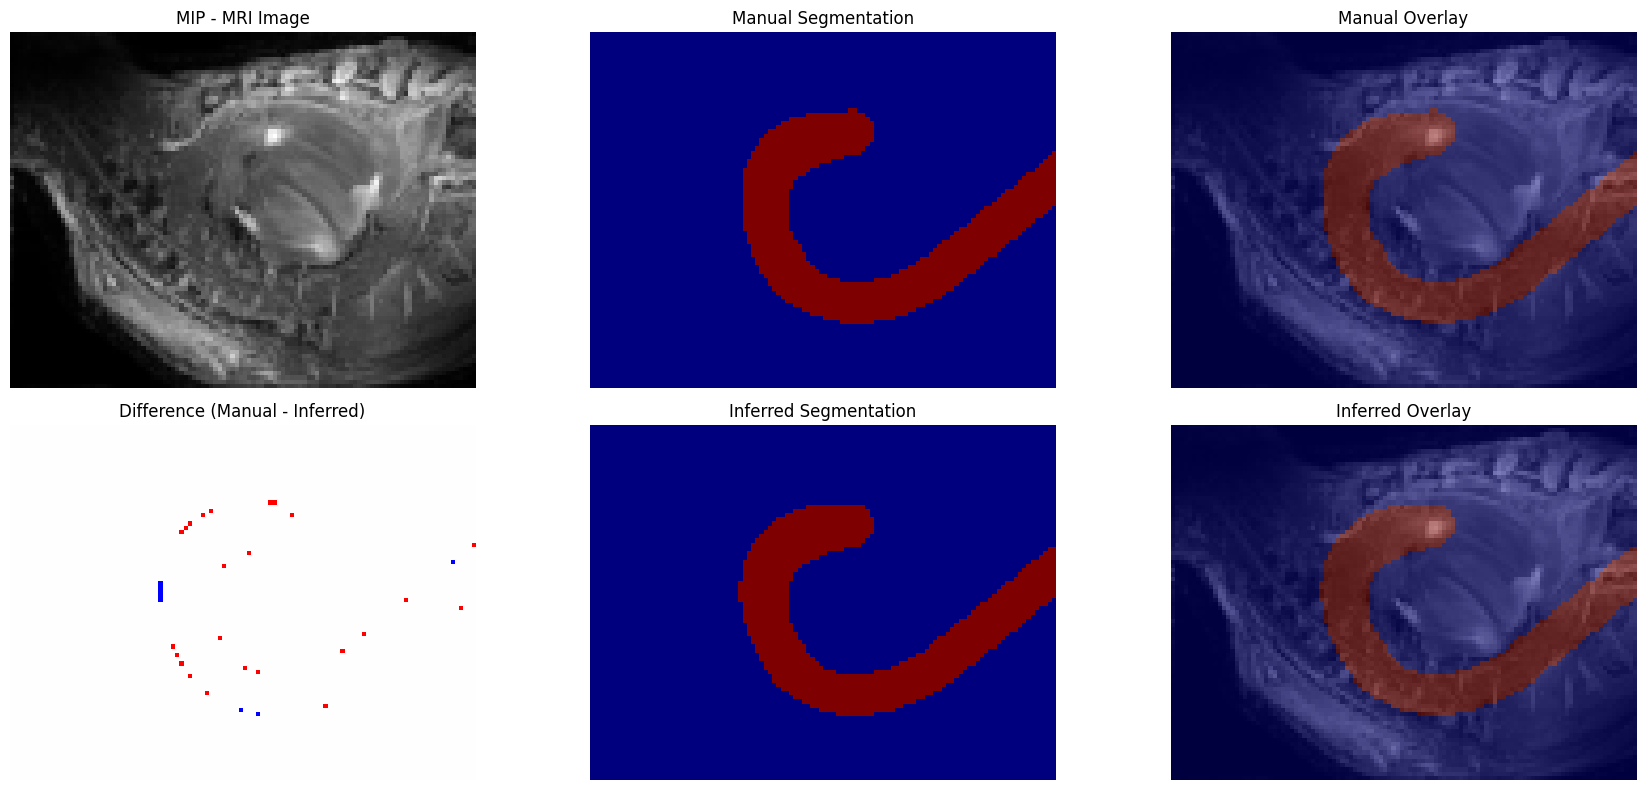

--------------------------------------------------------------------------------


In [13]:
def visualize_comparison(img_data, manual_seg, inferred_seg):
    mip_img = np.max(img_data, axis=2)
    mip_manual = np.max(manual_seg, axis=2)
    mip_inferred = np.max(inferred_seg, axis=2)

    plt.figure(figsize=(18, 8))

    # Original
    plt.subplot(2, 3, 1)
    plt.imshow(mip_img.T, cmap="gray", origin="lower")
    plt.title("MIP - MRI Image")
    plt.axis("off")

    # Manual mask
    plt.subplot(2, 3, 2)
    plt.imshow(mip_manual.T, cmap="jet", origin="lower")
    plt.title("Manual Segmentation")
    plt.axis("off")

    # Manual overlay
    plt.subplot(2, 3, 3)
    plt.imshow(mip_img.T, cmap="gray", origin="lower")
    plt.imshow(mip_manual.T, cmap="jet", alpha=0.5, origin="lower")
    plt.title("Manual Overlay")
    plt.axis("off")

    # Inferred mask
    plt.subplot(2, 3, 5)
    plt.imshow(mip_inferred.T, cmap="jet", origin="lower")
    plt.title("Inferred Segmentation")
    plt.axis("off")

    # Inferred overlay
    plt.subplot(2, 3, 6)
    plt.imshow(mip_img.T, cmap="gray", origin="lower")
    plt.imshow(mip_inferred.T, cmap="jet", alpha=0.5, origin="lower")
    plt.title("Inferred Overlay")
    plt.axis("off")

    # Difference (optional but useful!)
    diff = mip_manual - mip_inferred
    plt.subplot(2, 3, 4)
    plt.imshow(diff.T, cmap="bwr", origin="lower")
    plt.title("Difference (Manual - Inferred)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


print("COMPARISON: MANUAL vs INFERRED")

for img_path, manual_path, inferred_path in zip(sample_imgs, sample_segs, sample_infrenced_segs):
    img_data, _, _ = load_nifti(img_path)
    manual_seg, _, _ = load_nifti(manual_path)
    inferred_seg, _, _ = load_nifti(inferred_path)

    print(f"Image: {img_path.name}")
    visualize_comparison(img_data, manual_seg, inferred_seg)
    print("-" * 80)


In [6]:
import numpy as np
from scipy.spatial.distance import cdist

# ---------- Metrics ---------- #

def dice_score(gt, pred):
    gt = gt > 0
    pred = pred > 0
    intersection = np.sum(gt * pred)
    return (2. * intersection) / (np.sum(gt) + np.sum(pred) + 1e-8)


def iou_score(gt, pred):
    gt = gt > 0
    pred = pred > 0
    intersection = np.sum(gt & pred)
    union = np.sum(gt | pred)
    return intersection / (union + 1e-8)


def precision(gt, pred):
    gt = gt > 0
    pred = pred > 0
    tp = np.sum(gt & pred)
    fp = np.sum(~gt & pred)
    return tp / (tp + fp + 1e-8)


def recall(gt, pred):
    gt = gt > 0
    pred = pred > 0
    tp = np.sum(gt & pred)
    fn = np.sum(gt & ~pred)
    return tp / (tp + fn + 1e-8)


# ---------- Hausdorff Distance (HD95) ---------- #
def hausdorff_95(gt, pred):
    gt_points = np.argwhere(gt > 0)
    pred_points = np.argwhere(pred > 0)

    if len(gt_points) == 0 or len(pred_points) == 0:
        return np.nan

    distances = cdist(gt_points, pred_points)
    
    hd1 = np.percentile(np.min(distances, axis=1), 95)
    hd2 = np.percentile(np.min(distances, axis=0), 95)

    return max(hd1, hd2)


# ---------- Evaluation Loop ---------- #

results = []

for img_path, gt_path, pred_path in zip(sample_imgs, sample_segs, sample_infrenced_segs):

    img_data, _, _ = load_nifti(img_path)
    gt, _, _ = load_nifti(gt_path)
    pred, _, _ = load_nifti(pred_path)

    d = dice_score(gt, pred)
    iou = iou_score(gt, pred)
    p = precision(gt, pred)
    r = recall(gt, pred)
    hd = hausdorff_95(gt, pred)

    print(f"Image: {img_path.name}")
    print(f"Dice: {d:.4f}")
    print(f"IoU: {iou:.4f}")
    print(f"Precision: {p:.4f}")
    print(f"Recall: {r:.4f}")
    print(f"HD95: {hd:.2f}")
    print("-" * 50)

    results.append([d, iou, p, r, hd])

# ---------- Summary ---------- #

results = np.array(results)

print("\n===== DATASET SUMMARY =====")
print(f"Mean Dice: {np.nanmean(results[:,0]):.4f} ± {np.nanstd(results[:,0]):.4f}")
print(f"Mean IoU: {np.nanmean(results[:,1]):.4f}")
print(f"Mean Precision: {np.nanmean(results[:,2]):.4f}")
print(f"Mean Recall: {np.nanmean(results[:,3]):.4f}")
print(f"Mean HD95: {np.nanmean(results[:,4]):.2f}")

Image: VS022_f06_0000.nii.gz
Dice: 0.9738
IoU: 0.9489
Precision: 0.9716
Recall: 0.9760
HD95: 0.00
--------------------------------------------------
Image: VS005_f02_0000.nii.gz
Dice: 0.9753
IoU: 0.9518
Precision: 0.9644
Recall: 0.9865
HD95: 0.00
--------------------------------------------------
Image: VS052_f01_0000.nii.gz
Dice: 0.9777
IoU: 0.9564
Precision: 0.9769
Recall: 0.9785
HD95: 0.00
--------------------------------------------------
Image: VS047_f03_0000.nii.gz
Dice: 0.9669
IoU: 0.9359
Precision: 0.9438
Recall: 0.9912
HD95: 1.00
--------------------------------------------------
Image: VS042_f14_0000.nii.gz
Dice: 0.9775
IoU: 0.9560
Precision: 0.9787
Recall: 0.9762
HD95: 0.00
--------------------------------------------------
Image: VS026_f21_0000.nii.gz
Dice: 0.9752
IoU: 0.9516
Precision: 0.9800
Recall: 0.9705
HD95: 0.00
--------------------------------------------------
Image: VS019_f19_0000.nii.gz
Dice: 0.9792
IoU: 0.9592
Precision: 0.9747
Recall: 0.9836
HD95: 0.00
--------